In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import cv2
import os
import numpy as np

In [2]:
collagen = 4 # can be 2 or 4
day = 0 # can be 0 or 1
section = 1 # can be 1 or 2

path = f'202505_{collagen}/D{day}/s{section}'

condition_id = (collagen,day,section)

In [3]:
# diccionarios de mapeo
params_map = {
    # Collagen = 2
    (2, 0, 1): (60,470,0,890),
    (2, 0, 2): (60,420,0,890),
    (2, 1, 1): (60,470,0,890), 
    (2, 1, 2): (60,470,0,890),
    
    # Collagen = 4
    (4, 0, 1): (60,470,0,940),
    (4, 0, 2): (60,470,0,920),
    (4, 1, 1): (60,470,0,940), 
    (4, 1, 2): (60,470,0,910),
}

#### parameters
[x_inicio,x_fin,y_inicio,y_fin] = params_map[condition_id]

In [4]:
vidcap = cv2.VideoCapture('D:/OneDrive - unizar.es/I3A/MPA_JAJ/1_DATA/GBM_IMMUNE/PBMC_videos/may2025/'+path+'/raw_video.avi')
# Obtener tamaño de los frames
width  = int(vidcap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(vidcap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps    = vidcap.get(cv2.CAP_PROP_FPS)
nframes = int(vidcap.get(cv2.CAP_PROP_FRAME_COUNT))

print(f"Tamaño del vídeo: {width}x{height}")
print(f"FPS: {fps}")
print(f"Número total de frames: {nframes}")

success,image = vidcap.read()
count = 0
while success:
  cv2.imwrite("D:/OneDrive - unizar.es/I3A/MPA_JAJ/1_DATA/GBM_IMMUNE/PBMC_videos/may2025/"+path+"/frame%d.png" % count, image)     # save frame as PNG file      
  success,image = vidcap.read()
  print('Read a new frame: ', success)
  count += 1

Tamaño del vídeo: 969x516
FPS: 10.0
Número total de frames: 60
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
Read a new frame:  True
R

In [5]:
nombre_directorio = "processed_frames"
ruta = os.path.join("D:/OneDrive - unizar.es/I3A/MPA_JAJ/1_DATA/GBM_IMMUNE/PBMC_videos/may2025/",path,nombre_directorio)
if not os.path.exists(ruta):
    # Crear el directorio si no existe
    os.makedirs(ruta)
    print(f"Directorio '{nombre_directorio}' creado con éxito.")
else:
    print(f"El directorio '{nombre_directorio}' ya existe.")

El directorio 'processed_frames' ya existe.


In [6]:
for i in range(count):
    imagen_original = cv2.imread('D:/OneDrive - unizar.es/I3A/MPA_JAJ/1_DATA/GBM_IMMUNE/PBMC_videos/may2025/'+path+'/frame%d.png' % i) 
    imagen_recortada = imagen_original[x_inicio:x_fin,y_inicio:y_fin,:] 
    cv2.imwrite("D:/OneDrive - unizar.es/I3A/MPA_JAJ/1_DATA/GBM_IMMUNE/PBMC_videos/may2025/"+path+"/processed_frames/recortada_frame%d.png" % i, imagen_recortada)     # save frame as PNG file 

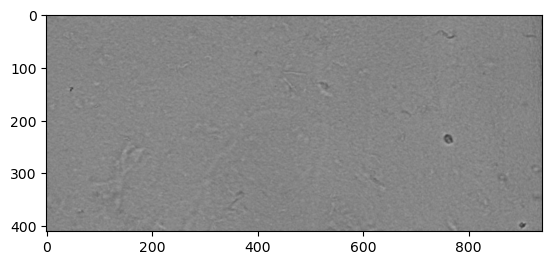

In [7]:
plt.imshow(imagen_recortada)

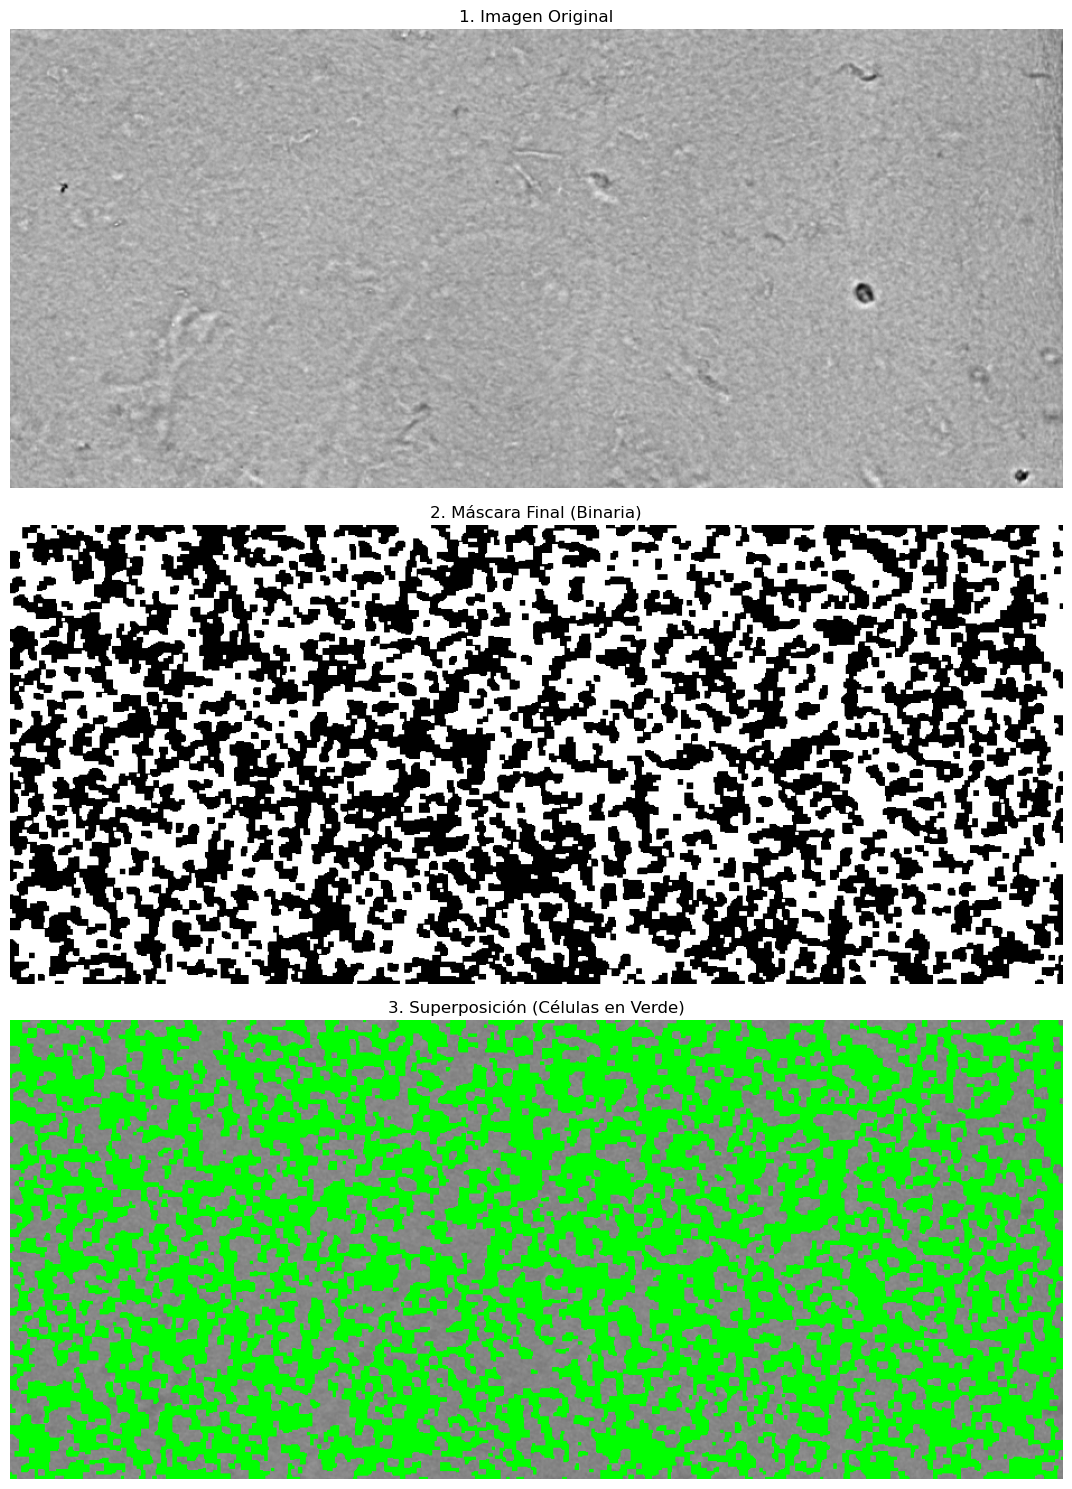

In [8]:
# PROCESADO DE LA IMAGEN
img = cv2.cvtColor(imagen_recortada, cv2.COLOR_BGR2GRAY)

blurred = cv2.GaussianBlur(img, (5, 5), 0)


# Definir el elemento estructurante (kernel) del tamaño aproximado de las células
# Un kernel circular es ideal para células esféricas
kernel_size = 7
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel_size, kernel_size))

# 2. Aplicar Top-Hat (Detecta células CLARAS/BRILLANTES sobre fondo oscuro)
tophat = cv2.morphologyEx(blurred, cv2.MORPH_TOPHAT, kernel)

# 3. Aplicar Black-Hat (Detecta células OSCURAS/NEGRAS sobre fondo claro)
blackhat = cv2.morphologyEx(blurred, cv2.MORPH_BLACKHAT, kernel)

# 4. Combinar y Umbralizar
# Sumamos los resultados. Ambos mapas de salida contienen píxeles brillantes
# en las ubicaciones de las células.
combined_contrast = cv2.add(tophat, blackhat)

# Aplica Umbralización de Otsu al resultado combinado
# Otsu encuentra el umbral óptimo para separar el fondo del objeto
_, final_mask = cv2.threshold(combined_contrast, 0, 255, 
                                 cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 5. Limpieza (Opcional, pero recomendado)
final_mask = cv2.morphologyEx(final_mask, cv2.MORPH_CLOSE, np.ones((5,5), np.uint8))
final_mask = cv2.morphologyEx(final_mask, cv2.MORPH_OPEN, np.ones((3,3), np.uint8))
final_mask_white = cv2.bitwise_not(final_mask) 

# Visualización
fig, axes = plt.subplots(3,1, figsize=(15, 15))

# Imagen Original
axes[0].imshow(img, cmap='gray')
axes[0].set_title('1. Imagen Original')

# Máscara binaria
axes[1].imshow(final_mask, cmap='gray')
axes[1].set_title('2. Máscara Final (Binaria)')

# Superposición (Opcional: resaltar las células en la imagen original)
# Creamos una imagen de color para la superposición
img_color = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)

# Aplicamos la máscara para resaltar el área segmentada (usando color verde)
# La máscara tiene que ser de 3 canales para hacer la superposición de color
mask_3ch = cv2.cvtColor(final_mask_white, cv2.COLOR_GRAY2BGR)
masked_image = np.where(mask_3ch == 0, [0, 255, 0], img_color) # Píxeles blancos de la máscara son verdes

axes[2].imshow(cv2.cvtColor(masked_image.astype(np.uint8), cv2.COLOR_BGR2RGB))
axes[2].set_title('3. Superposición (Células en Verde)')

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()

# La variable 'final_mask' contiene la matriz de la máscara binaria.

In [9]:
def generar_mascara(imagen_recortada):

    img = cv2.cvtColor(imagen_recortada, cv2.COLOR_BGR2GRAY)

    blurred = cv2.GaussianBlur(img, (5, 5), 0)


    # Definir el elemento estructurante (kernel) del tamaño aproximado de las células
    # Un kernel circular es ideal para células esféricas
    kernel_size = 7
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel_size, kernel_size))

    # 2. Aplicar Top-Hat (Detecta células CLARAS/BRILLANTES sobre fondo oscuro)
    tophat = cv2.morphologyEx(blurred, cv2.MORPH_TOPHAT, kernel)

    # 3. Aplicar Black-Hat (Detecta células OSCURAS/NEGRAS sobre fondo claro)
    blackhat = cv2.morphologyEx(blurred, cv2.MORPH_BLACKHAT, kernel)

    # 4. Combinar y Umbralizar
    # Sumamos los resultados. Ambos mapas de salida contienen píxeles brillantes
    # en las ubicaciones de las células.
    combined_contrast = cv2.add(tophat, blackhat)

    # Aplica Umbralización de Otsu al resultado combinado
    # Otsu encuentra el umbral óptimo para separar el fondo del objeto
    _, final_mask = cv2.threshold(combined_contrast, 0, 255, 
                                     cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # 5. Limpieza (Opcional, pero recomendado)
    final_mask = cv2.morphologyEx(final_mask, cv2.MORPH_CLOSE, np.ones((5,5), np.uint8))
    final_mask = cv2.morphologyEx(final_mask, cv2.MORPH_OPEN, np.ones((3,3), np.uint8))
    
    return final_mask



In [10]:
for i in range(count):
    
    # 1. Cargar la imagen (OpenCV la carga como BGR por defecto)
    imagen_recortada = cv2.imread("D:/OneDrive - unizar.es/I3A/MPA_JAJ/1_DATA/GBM_IMMUNE/PBMC_videos/may2025/"+path+"/processed_frames/recortada_frame%d.png" % i)
    
    if imagen_recortada is None:
        print(f"Advertencia: No se encontró la imagen: {input_filename}")
        continue
        
    # 3. Generar la máscara
    mask = generar_mascara(imagen_recortada)
    
    # 4. Guardar la máscara binaria resultante
    output_filename = os.path.join("D:/OneDrive - unizar.es/I3A/MPA_JAJ/1_DATA/GBM_IMMUNE/PBMC_videos/may2025/"+path+"/processed_frames/mask_frame%d.png" % i,)
    cv2.imwrite(output_filename, mask)

print("Procesamiento de todas las máscaras completado.")

Procesamiento de todas las máscaras completado.
